# Bài toán 1 — Khám phá mối quan hệ giữa vị trí và kỹ năng chuyên môn

Mục tiêu là tìm các luật `ROLE → skill` và đánh giá xem lọc luật có giúp xếp hạng kỹ năng tốt hơn cách đếm tần suất skill trong từng role hay không. So sánh Apriori và FP-Growth với baseline tần suất theo role bằng kiểm định chéo phân tầng 5-fold.

> **Phiên bản role mới:** `role_group` ở notebook này là cặp `{role, cấp bậc kinh nghiệm}` (cột `role_exp` tạo ở notebook EDA, ví dụ `Backend / Fullstack Dev | Senior`). Phần còn lại của bài toán giữ nguyên: luật `ROLE → skill` nay chính là luật `{role, exp} → skill`.

## 1. Dữ liệu và thiết kế đánh giá

Loại nhóm role `Other` và các tin không trích xuất được kỹ năng chuyên môn. Mỗi fold vẫn có đủ các nhóm role. Baseline xếp hạng kỹ năng theo tần suất trong phần train của chính role đó, nên đây là đối chứng trực tiếp cho luật `ROLE → skill`.

In [1]:
import ast, json, math, time, tracemalloc
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from mlxtend.frequent_patterns import apriori, association_rules, fpgrowth
from sklearn.model_selection import StratifiedKFold

DATA_DIR = Path("../data/processed")
RESULT_DIR = Path("../result/problem_1")
FIGURES_DIR = RESULT_DIR / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
RANDOM_STATE, N_SPLITS = 42, 5
MIN_SUPPORT_COUNT, MIN_CONFIDENCE, MIN_LIFT = 8, 0.20, 1.20
MAX_ITEMSET_LENGTH = 2  # one role + one skill; longer consequents are redundant here
TOP_K_VALUES = [5, 10]

def parse_skill_list(value):
    if isinstance(value, list): parsed = value
    elif isinstance(value, str):
        try: parsed = ast.literal_eval(value)
        except (ValueError, SyntaxError): parsed = []
    else: parsed = []
    if not isinstance(parsed, list): return []
    return list(dict.fromkeys(x.strip() for x in parsed if isinstance(x, str) and x.strip()))

jobs_all = pd.read_csv(DATA_DIR / "processed_jobs.csv")
jobs_all["skills_final"] = jobs_all["skills_final"].apply(parse_skill_list)
jobs_all["role_group"] = jobs_all["role_exp"]   # role mới = {role, cấp bậc}; "Other" vẫn là "Other" nên vẫn bị loại bên dưới
role_mask = jobs_all["role_group"].fillna("Other").ne("Other")
jobs = jobs_all.loc[role_mask].reset_index(drop=True)
transactions = pd.read_csv(DATA_DIR / "transaction_matrix.csv").replace(
    {"True": True, "False": False}
).fillna(False).astype(bool).reset_index(drop=True)
if len(jobs) != len(transactions):
    raise ValueError("processed_jobs và transaction_matrix không khớp thứ tự dòng sau khi bỏ Other")
role_cols = [c for c in transactions if c.startswith("ROLE_")]
skill_cols = [c for c in transactions if not c.startswith("ROLE_")]
role_from_matrix = transactions[role_cols].idxmax(axis=1).str.replace("ROLE_", "", n=1, regex=False)
if not role_from_matrix.equals(jobs["role_group"].reset_index(drop=True)):
    raise ValueError("Nhãn role không khớp thứ tự dòng của ma trận giao dịch")
has_skills = jobs["skills_final"].map(bool)
excluded_empty = int((~has_skills).sum())
jobs = jobs.loc[has_skills].reset_index(drop=True)
transactions = transactions.loc[has_skills].reset_index(drop=True)
print(f"Tin dùng được: {len(jobs)}; loại do thiếu skill: {excluded_empty}; số role: {jobs.role_group.nunique()}")
display(jobs["role_group"].value_counts().rename("Số tin").to_frame())

Tin dùng được: 1501; loại do thiếu skill: 329; số role: 39


,Số tin
role_group,
Designer / Creative | Fresher,177
BA / PM / Product | Junior,148
Designer / Creative | Junior,146
Backend / Fullstack Dev | Junior,133
DevOps / Infra / Security | Junior,104
Designer / Creative | Intern,66
BA / PM / Product | Senior,60
BA / PM / Product | Fresher,49
DevOps / Infra / Security | Fresher,48


## 2. Khai phá và xếp hạng luật

Mỗi luật phải được hỗ trợ bởi ít nhất 8 tin tuyển dụng trong tập train. `max_len=2` là đủ cho dạng `ROLE → skill`; vế phải dài hơn chỉ tạo tổ hợp dư thừa cho bài toán này. Baseline xếp hạng tất cả skill quan sát được trong role mà không áp ngưỡng luật.

In [2]:
def mine_rules(matrix, method):
    miner = apriori if method == "Apriori" else fpgrowth
    freq = miner(matrix, min_support=MIN_SUPPORT_COUNT / len(matrix),
                 use_colnames=True, max_len=MAX_ITEMSET_LENGTH)
    cols = ["role_group", "skill", "support", "support_count", "confidence", "lift"]
    if freq.empty or not freq["itemsets"].map(len).ge(2).any():
        return freq, pd.DataFrame(columns=cols)
    rules = association_rules(freq, metric="confidence", min_threshold=MIN_CONFIDENCE)
    if rules.empty: return freq, pd.DataFrame(columns=cols)
    rules = rules[
        rules.antecedents.map(lambda x: len(x) == 1 and str(next(iter(x))).startswith("ROLE_"))
        & rules.consequents.map(lambda x: len(x) == 1 and not str(next(iter(x))).startswith("ROLE_"))
        & (rules.lift >= MIN_LIFT)
        & (rules.support * len(matrix) >= MIN_SUPPORT_COUNT - 1e-9)
    ].copy()
    if rules.empty: return freq, pd.DataFrame(columns=cols)
    rules["role_group"] = rules.antecedents.map(lambda x: str(next(iter(x))).replace("ROLE_", "", 1))
    rules["skill"] = rules.consequents.map(lambda x: str(next(iter(x))))
    rules["support_count"] = (rules.support * len(matrix)).round().astype(int)
    return freq, rules[cols].sort_values(
        ["role_group", "confidence", "lift", "support"],
        ascending=[True, False, False, False]).reset_index(drop=True)

def popularity_rankings(train_jobs, train_matrix):
    rankings = {}
    role_values = train_jobs.role_group.reset_index(drop=True)
    skills = train_matrix[skill_cols].reset_index(drop=True)
    for role in role_values.unique():
        positions = np.flatnonzero(role_values.eq(role).to_numpy())
        rankings[role] = skills.iloc[positions].sum().sort_values(
            ascending=False, kind="stable").index.tolist()
    return rankings

def rule_rankings(rules, roles):
    result = {role: [] for role in roles}
    for role, group in rules.groupby("role_group"):
        result[role] = group.sort_values(
            ["confidence", "lift", "support"], ascending=False).skill.drop_duplicates().tolist()
    return result

def metrics_at_k(prediction, relevant, k):
    relevant = set(relevant) & set(skill_cols)
    prediction = list(dict.fromkeys(prediction))[:k]
    hits = [int(x in relevant) for x in prediction]
    dcg = sum(hit / math.log2(i + 2) for i, hit in enumerate(hits))
    idcg = sum(1 / math.log2(i + 2) for i in range(min(k, len(relevant))))
    return {"Precision@K": sum(hits) / k,
            "Recall@K": sum(hits) / len(relevant) if relevant else 0.0,
            "Hit@K": float(any(hits)), "NDCG@K": dcg / idcg if idcg else 0.0,
            "Recommendation coverage": len(prediction) / k}

## 3. Đánh giá phân tầng 5-fold

Mỗi mô hình được huấn luyện trên bốn fold và đánh giá trên fold còn lại. Báo cáo trung bình và độ lệch chuẩn qua năm fold. `Precision@K` đo tỷ lệ gợi ý đúng trong K vị trí; `Recall@K` đo phần kỹ năng mục tiêu tìm được; `Hit@K` cho biết có ít nhất một gợi ý đúng hay không; `NDCG@K` đánh giá thứ tự xếp hạng.


In [3]:
splitter = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE)
fold_quality, fold_benchmarks = [], []
fold_itemsets_equal = []
for fold, (tr, te) in enumerate(splitter.split(np.zeros(len(jobs)), jobs.role_group), 1):
    train_jobs, test_jobs = jobs.iloc[tr].reset_index(drop=True), jobs.iloc[te].reset_index(drop=True)
    train_matrix = transactions.iloc[tr].reset_index(drop=True)
    rankings = {}
    itemset_maps = {}
    for method in ["Apriori", "FP-Growth"]:
        tracemalloc.start(); started = time.perf_counter()
        itemsets, rules = mine_rules(train_matrix, method)
        runtime = time.perf_counter() - started
        _, peak = tracemalloc.get_traced_memory(); tracemalloc.stop()
        rankings[method] = rule_rankings(rules, jobs.role_group.unique())
        fold_benchmarks.append({"fold": fold, "Model": method, "Runtime (s)": runtime,
            "Memory Usage (MB)": peak / 2**20, "Number of Rules": len(rules)})
        itemset_maps[method] = {frozenset(x) for x in itemsets.get("itemsets", [])}
    fold_itemsets_equal.append(itemset_maps["Apriori"] == itemset_maps["FP-Growth"])
    tracemalloc.start(); started = time.perf_counter()
    rankings["Phổ biến theo role"] = popularity_rankings(train_jobs, train_matrix)
    runtime = time.perf_counter() - started
    _, peak = tracemalloc.get_traced_memory(); tracemalloc.stop()
    fold_benchmarks.append({"fold": fold, "Model": "Phổ biến theo role", "Runtime (s)": runtime,
        "Memory Usage (MB)": peak / 2**20, "Number of Rules": np.nan})
    for name, ranking in rankings.items():
        for k in TOP_K_VALUES:
            row_scores = [metrics_at_k(ranking.get(row.role_group, []), row.skills_final, k)
                          for row in test_jobs.itertuples(index=False)]
            fold_quality.append({"fold": fold, "Model": name, "K": k,
                **{m: np.mean([x[m] for x in row_scores]) for m in row_scores[0]},
                "Test jobs": len(row_scores)})

fold_quality_df = pd.DataFrame(fold_quality)
metric_names = ["Precision@K", "Recall@K", "Hit@K", "NDCG@K", "Recommendation coverage"]
quality_df = fold_quality_df.groupby(["Model", "K"])[metric_names].agg(["mean", "std"]).reset_index()
quality_df.columns = ["Model", "K", *[f"{m}_{s}" for m in metric_names for s in ["mean", "std"]]]
quality_df["folds"] = N_SPLITS
bench_folds = pd.DataFrame(fold_benchmarks)
benchmark_df = bench_folds.groupby("Model").agg(
    **{"Runtime median (s)": ("Runtime (s)", "median"), "Runtime std (s)": ("Runtime (s)", "std"),
       "Number of Rules mean": ("Number of Rules", "mean"), "Number of Rules std": ("Number of Rules", "std"),
       "Memory Usage median (MB)": ("Memory Usage (MB)", "median"),
       "Memory Usage std (MB)": ("Memory Usage (MB)", "std")}).reset_index()
print("Itemsets Apriori/FP-Growth giống nhau ở mọi fold:", all(fold_itemsets_equal))
display(quality_df.rename(columns={"Model": "Mô hình"}).round(4)); display(benchmark_df.rename(columns={"Model": "Mô hình", "Runtime median (s)": "Runtime trung vị (giây)",
    "Runtime std (s)": "Độ lệch chuẩn runtime", "Number of Rules mean": "Số luật trung bình",
    "Number of Rules std": "Độ lệch chuẩn số luật", "Memory Usage median (MB)": "Bộ nhớ Python trung vị (MB)",
    "Memory Usage std (MB)": "Độ lệch chuẩn bộ nhớ"}).round(4))

c:\Users\Admin\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\model_selection\_split.py:812: UserWarning: The least populated class in y has only 1 members, which is less than n_splits=5.
  warnings.warn(


Itemsets Apriori/FP-Growth giống nhau ở mọi fold: True


,Mô hình,K,Precision@K_mean,Precision@K_std,Recall@K_mean,Recall@K_std,Hit@K_mean,Hit@K_std,NDCG@K_mean,NDCG@K_std,Recommendation coverage_mean,Recommendation coverage_std,folds
0,Apriori,5,0.2480,0.0068,0.2890,0.0187,0.5876,0.0149,0.3614,0.0183,0.6640,0.0208,5
1,Apriori,10,0.1515,0.0082,0.3183,0.0236,0.6109,0.0162,0.3497,0.0207,0.4577,0.0122,5
2,FP-Growth,5,0.2480,0.0068,0.2890,0.0187,0.5876,0.0149,0.3614,0.0183,0.6640,0.0208,5
3,FP-Growth,10,0.1515,0.0082,0.3183,0.0236,0.6109,0.0162,0.3497,0.0207,0.4577,0.0122,5
4,Phổ biến theo role,5,0.3123,0.0116,0.3851,0.0195,0.7421,0.0332,0.4474,0.0212,0.9993,0.0015,5
5,Phổ biến theo role,10,0.2290,0.0107,0.5220,0.0272,0.8434,0.0306,0.4817,0.0224,0.9993,0.0015,5


,Mô hình,Runtime trung vị (giây),Độ lệch chuẩn runtime,Số luật trung bình,Độ lệch chuẩn số luật,Bộ nhớ Python trung vị (MB),Độ lệch chuẩn bộ nhớ
0,Apriori,0.1717,0.0354,104.4,2.0736,65.9227,1.6140
1,FP-Growth,0.3566,0.0674,104.4,2.0736,3.4390,0.0995
2,Phổ biến theo role,0.0316,0.0100,NaN,NaN,0.3655,0.0049


## 4. Luật cuối cùng và độ bao phủ theo role

Các file luật được khai phá từ toàn bộ tin đủ điều kiện để tiện xem xét; điểm chất lượng ở trên chỉ được tính từ các fold giữ lại. Bảng theo role cho thấy rõ role nào có ít hoặc không có luật.

In [4]:
full_apriori_itemsets, rules_apriori = mine_rules(transactions, "Apriori")
full_fp_itemsets, rules_fpgrowth = mine_rules(transactions, "FP-Growth")
print("Itemsets trên toàn bộ dữ liệu giống nhau:",
      {frozenset(x) for x in full_apriori_itemsets.get("itemsets", [])}
      == {frozenset(x) for x in full_fp_itemsets.get("itemsets", [])})
coverage_rows = []
for role in sorted(jobs.role_group.unique()):
    a = rules_apriori[rules_apriori.role_group.eq(role)]
    f = rules_fpgrowth[rules_fpgrowth.role_group.eq(role)]
    idx = jobs.role_group.eq(role).to_numpy()
    coverage_rows.append({"role_group": role, "usable_jobs": int(idx.sum()),
        "apriori_rules": len(a), "apriori_candidate_skills": a.skill.nunique(),
        "fpgrowth_rules": len(f), "fpgrowth_candidate_skills": f.skill.nunique(),
        "role_popularity_candidate_skills": int((transactions.loc[idx, skill_cols].sum() > 0).sum())})
role_coverage_df = pd.DataFrame(coverage_rows)
display(role_coverage_df.rename(columns={"role_group": "Nhóm role"}))

Itemsets trên toàn bộ dữ liệu giống nhau: True


,Nhóm role,usable_jobs,apriori_rules,apriori_candidate_skills,fpgrowth_rules,fpgrowth_candidate_skills,role_popularity_candidate_skills
0,BA / PM / Product | Fresher,49,2,2,2,2,67
1,BA / PM / Product | Intern,22,1,1,1,1,36
2,BA / PM / Product | Junior,148,1,1,1,1,117
3,BA / PM / Product | Senior,60,3,3,3,3,104
4,Backend / Fullstack Dev | Fresher,42,10,10,10,10,86
5,Backend / Fullstack Dev | Intern,28,2,2,2,2,69
6,Backend / Fullstack Dev | Junior,133,13,13,13,13,132
7,Backend / Fullstack Dev | Senior,39,18,18,18,18,98
8,Data / AI | Fresher,15,1,1,1,1,42
9,Data / AI | Intern,10,0,0,0,0,34


## 5. Biểu đồ và file kết quả

Các file được lưu trong `result/problem_1/`. Bộ nhớ là lượng cấp phát đỉnh của Python đo bằng `tracemalloc`, không bao gồm toàn bộ phần bộ nhớ native do NumPy/pandas sử dụng.

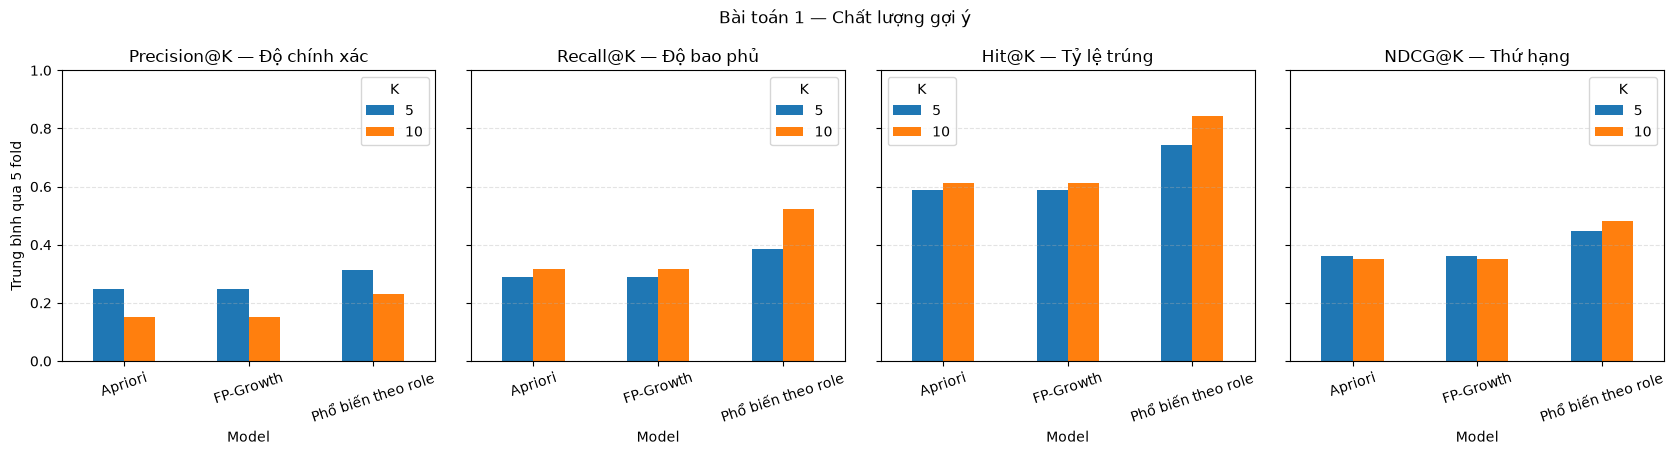

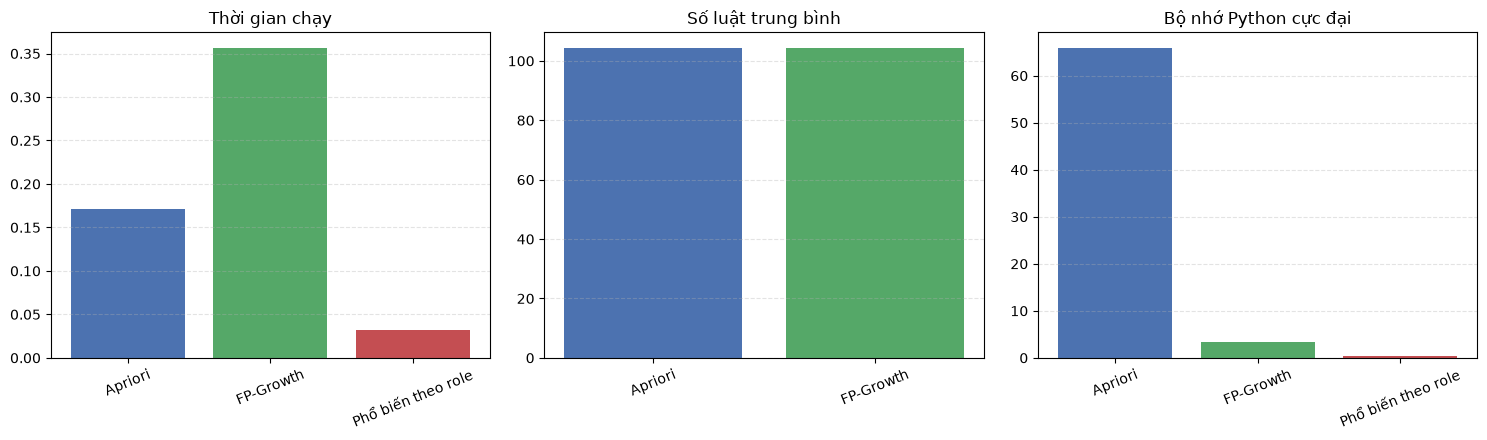

Đã lưu kết quả tại: D:\SKILL_REComMENDATIon_Data_Mining\skill-recommendation-using-association-rules\result\problem_1


In [5]:
short = {"Apriori": "Apriori", "FP-Growth": "FP-Growth", "Phổ biến theo role": "Phổ biến theo role"}
plot_df = quality_df.copy(); plot_df["Model"] = plot_df.Model.map(short)
fig, axes = plt.subplots(1, 4, figsize=(17, 4.6), sharey=True)
for ax, metric, vn_title in zip(axes, ["Precision@K", "Recall@K", "Hit@K", "NDCG@K"],
    ["Precision@K — Độ chính xác", "Recall@K — Độ bao phủ", "Hit@K — Tỷ lệ trúng", "NDCG@K — Thứ hạng"]):
    plot_df.pivot(index="Model", columns="K", values=f"{metric}_mean").plot(
        kind="bar", ax=ax, ylim=(0, 1), rot=18)
    ax.set_title(vn_title); ax.set_ylabel("Trung bình qua 5 fold")
    ax.grid(axis="y", linestyle="--", alpha=.35); ax.legend(title="K")
fig.suptitle("Bài toán 1 — Chất lượng gợi ý"); fig.tight_layout()
fig.savefig(FIGURES_DIR / "recommendation_quality.png", dpi=180, bbox_inches="tight"); plt.show()
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, col, title in zip(axes, ["Runtime median (s)", "Number of Rules mean", "Memory Usage median (MB)"],
                          ["Thời gian chạy", "Số luật trung bình", "Bộ nhớ Python cực đại"]):
    ax.bar(benchmark_df.Model, benchmark_df[col], color=["#4C72B0", "#55A868", "#C44E52"])
    ax.set_title(title); ax.tick_params(axis="x", rotation=22); ax.grid(axis="y", linestyle="--", alpha=.35)
fig.tight_layout(); fig.savefig(FIGURES_DIR / "benchmark.png", dpi=180, bbox_inches="tight"); plt.show()
fold_quality_df.to_csv(RESULT_DIR / "quality_metrics_by_fold.csv", index=False, encoding="utf-8-sig")
quality_df.to_csv(RESULT_DIR / "quality_metrics.csv", index=False, encoding="utf-8-sig")
benchmark_df.to_csv(RESULT_DIR / "benchmark.csv", index=False, encoding="utf-8-sig")
role_coverage_df.to_csv(RESULT_DIR / "role_coverage.csv", index=False, encoding="utf-8-sig")
rules_apriori.to_csv(RESULT_DIR / "rules_apriori.csv", index=False, encoding="utf-8-sig")
rules_fpgrowth.to_csv(RESULT_DIR / "rules_fpgrowth.csv", index=False, encoding="utf-8-sig")
print("Đã lưu kết quả tại:", RESULT_DIR.resolve())

## 6. Diễn giải

Dùng baseline tần suất theo role làm mốc chính. Có thể thấy Baseline tốt hơn, kết luận phù hợp là lọc luật `ROLE → skill` chưa cải thiện thứ hạng trong cấu hình này; tuy vậy các luật vẫn có ích để diễn giải support, confidence và lift. Thông qua đó sẽ tiến hành Bài toán 2 kiểm tra ngữ cảnh cá nhân hóa `{role, known skills} → next skill` cải thiện đáng kể chất lượng đề xuất skill thông qua các skill đã biết theo ngành đó.